#Introduction to Linear Algebra and the world of probablitites

In this work-sheet, we shall do two activities. First of all we shall check the power of SVD. Then we shall check how may we generate data from an arbitrary distribution (given that we have the ability to generate data from a uniform distribution).

##Singular Value Decomposition
Lets load an image and try to do it's SVD.

Please note the way to access an image from your Google drive. Change the code accordingly (and load an image in your Google drive) to access to your own image!

Mark that we shall be using PIL's Image library, a useful set of powerful algorithms for image processing.


In [1]:
import matplotlib.pyplot as plt
import numpy as np
import time

from PIL import Image

In [2]:
# # Load the Drive helper and mount
# from google.colab import drive
# drive.mount('/content/drive')

Lets load the image and convert that to a gray-scale version (so that we can treat it just like a 2D matrix). What will happen if its not gray-scale?

Mark how we have used the command $matrix$ to generate a matrix from the image!

In [3]:
img = Image.open("/Users/krzysiek/Desktop/ML4Space/my_photo.jpg")
imggray = img.convert('L')

/var/folders/zj/lzpt73xj0l5bd2yk4zcdzr7m0000gn/T/ipykernel_84055/3979908375.py:1: DeprecationWarning: Image.Image.getdata is deprecated and will be removed in Pillow 14 (2027-10-15). Use get_flattened_data instead.
  imgmat = np.array(list(imggray.getdata(band=0)), float)
/var/folders/zj/lzpt73xj0l5bd2yk4zcdzr7m0000gn/T/ipykernel_84055/3979908375.py:2: DeprecationWarning: Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view using np.reshape (with copy=False if needed).
  imgmat.shape = (imggray.size[1], imggray.size[0])


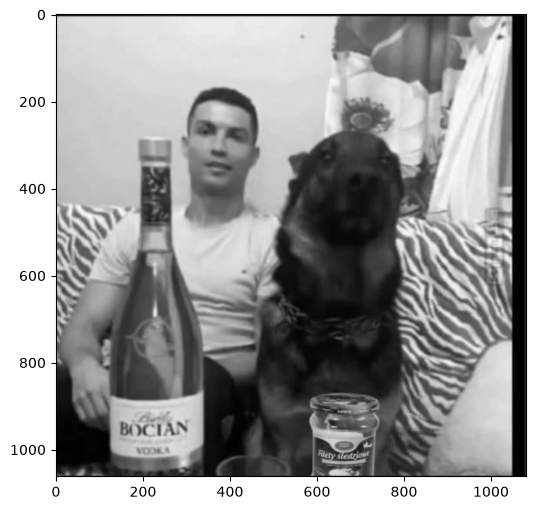

In [4]:
imgmat = np.array(list(imggray.getdata(band=0)), float)
imgmat.shape = (imggray.size[1], imggray.size[0])
imgmat = np.matrix(imgmat)
plt.figure(figsize=(9,6))
plt.imshow(imgmat, cmap='gray')

###SVD

We can directly use the $svd$ command from Numpy to operate SVD on the matrix.

Lets first check how the image will look if we only use a single vector to reconstruct the image.

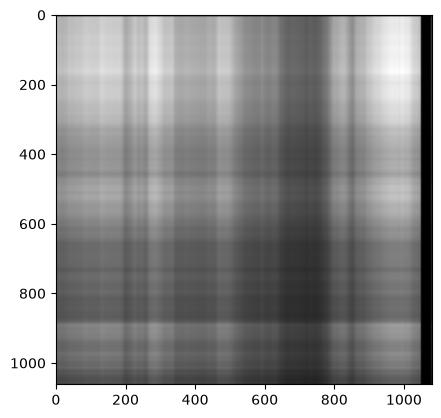

In [5]:
U, sigma, V = np.linalg.svd(imgmat)
reconstimg = np.matrix(U[:, :1]) * np.diag(sigma[:1]) * np.matrix(V[:1, :])
plt.imshow(reconstimg, cmap='gray');


Now lets check how does the sigma vector look like.

What do you observe? How many vecotrs can we use to get a decent reconstruction of the image?
What will happen if we omit the first 1-2 vectors (corresponding to the largest eigen values)?

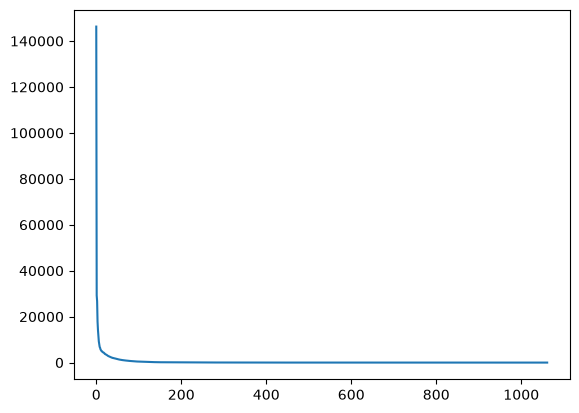

In [6]:
U.shape
sigma.shape
plt.plot(sigma)

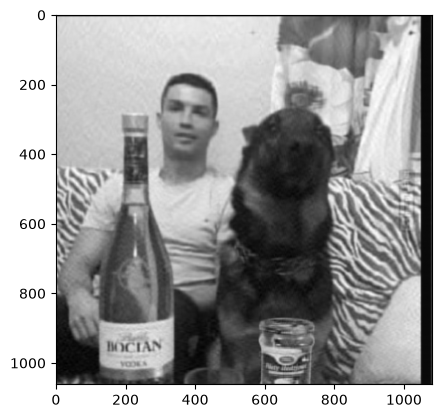

In [7]:
i = 70
j = 0
reconstimg = np.matrix(U[:, j:i]) * np.diag(sigma[j:i]) * np.matrix(V[j:i, :])
plt.imshow(reconstimg, cmap='gray');

## Satellite images — SVD by terrain

Using **Sentinel-2 L2A** true-color crops:
- **Forest (Poland):** Białowieża
- **Urban (Poland):** Warsaw
- **Ocean (Portugal):** Atlantic near Cascais 

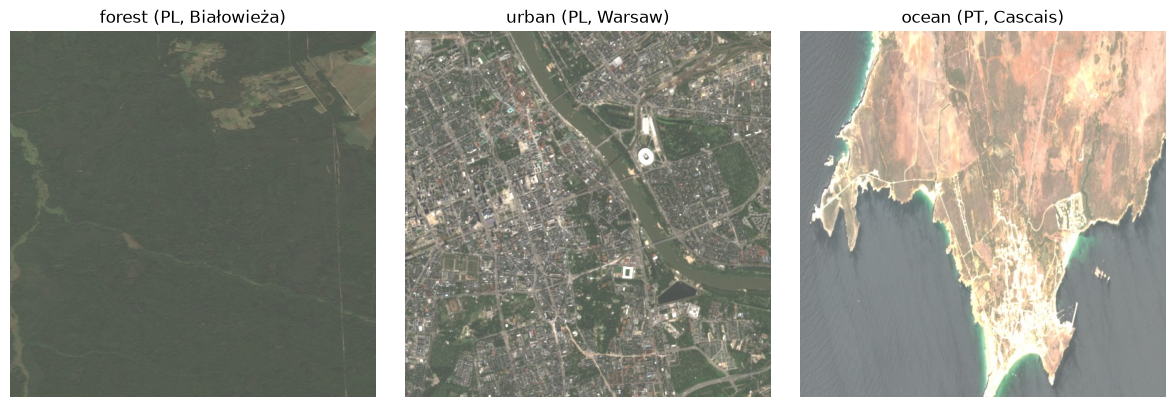

forest (PL, Białowieża)      shape=(400, 400)  k@95%=  1  k@99%=  1  rank=400
urban (PL, Warsaw)           shape=(400, 400)  k@95%=  1  k@99%= 42  rank=400
ocean (PT, Cascais)          shape=(400, 400)  k@95%=  1  k@99%=  6  rank=400


In [8]:
from pathlib import Path

IMG_DIR = Path("satellite_images") 

terrains = {
    "forest (PL, Białowieża)": IMG_DIR / "forest_poland.jpg",
    "urban (PL, Warsaw)": IMG_DIR / "urban_poland.jpg",
    "ocean (PT, Cascais)": IMG_DIR / "ocean_portugal.jpg",
}

def load_gray_matrix(path, max_side=400):
    img = Image.open(path).convert("L")
    w, h = img.size
    scale = max_side / max(w, h)
    if scale < 1:
        img = img.resize((int(w * scale), int(h * scale)))
    return np.asarray(img, dtype=float)

def k_for_energy(sigma, frac=0.99):
    energy = np.cumsum(sigma**2) / np.sum(sigma**2)
    return int(np.searchsorted(energy, frac)) + 1

# preview the three satellite scenes
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, (name, path) in zip(axes, terrains.items()):
    ax.imshow(Image.open(path))
    ax.set_title(name)
    ax.axis("off")
plt.tight_layout()
plt.show()

svds = {}
for name, path in terrains.items():
    mat = load_gray_matrix(path)
    U, sigma, Vt = np.linalg.svd(mat, full_matrices=False)
    svds[name] = (mat, U, sigma, Vt)
    print(
        f"{name:28s} shape={mat.shape}  "
        f"k@95%={k_for_energy(sigma, 0.95):3d}  "
        f"k@99%={k_for_energy(sigma, 0.99):3d}  rank={len(sigma)}"
    )



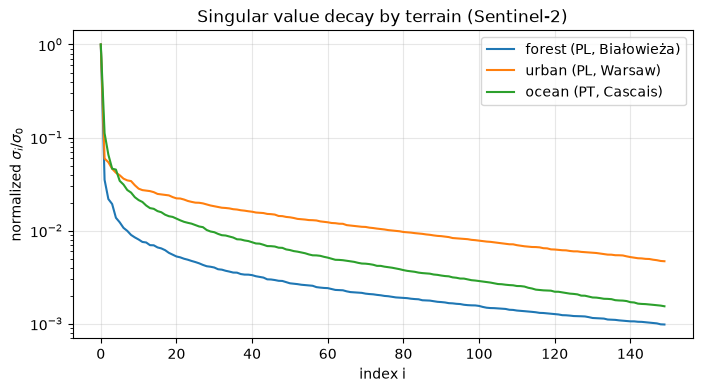

In [ ]:
# Singular-value decay - smoother scenes (forest) drop faster
plt.figure(figsize=(8, 4))
for name, (mat, U, sigma, Vt) in svds.items():
    plt.semilogy(sigma[:150] / sigma[0], label=name)
plt.xlabel("index i")
plt.ylabel(r"normalized $\sigma_i / \sigma_0$")
plt.title("Singular value decay by terrain (Sentinel-2)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()



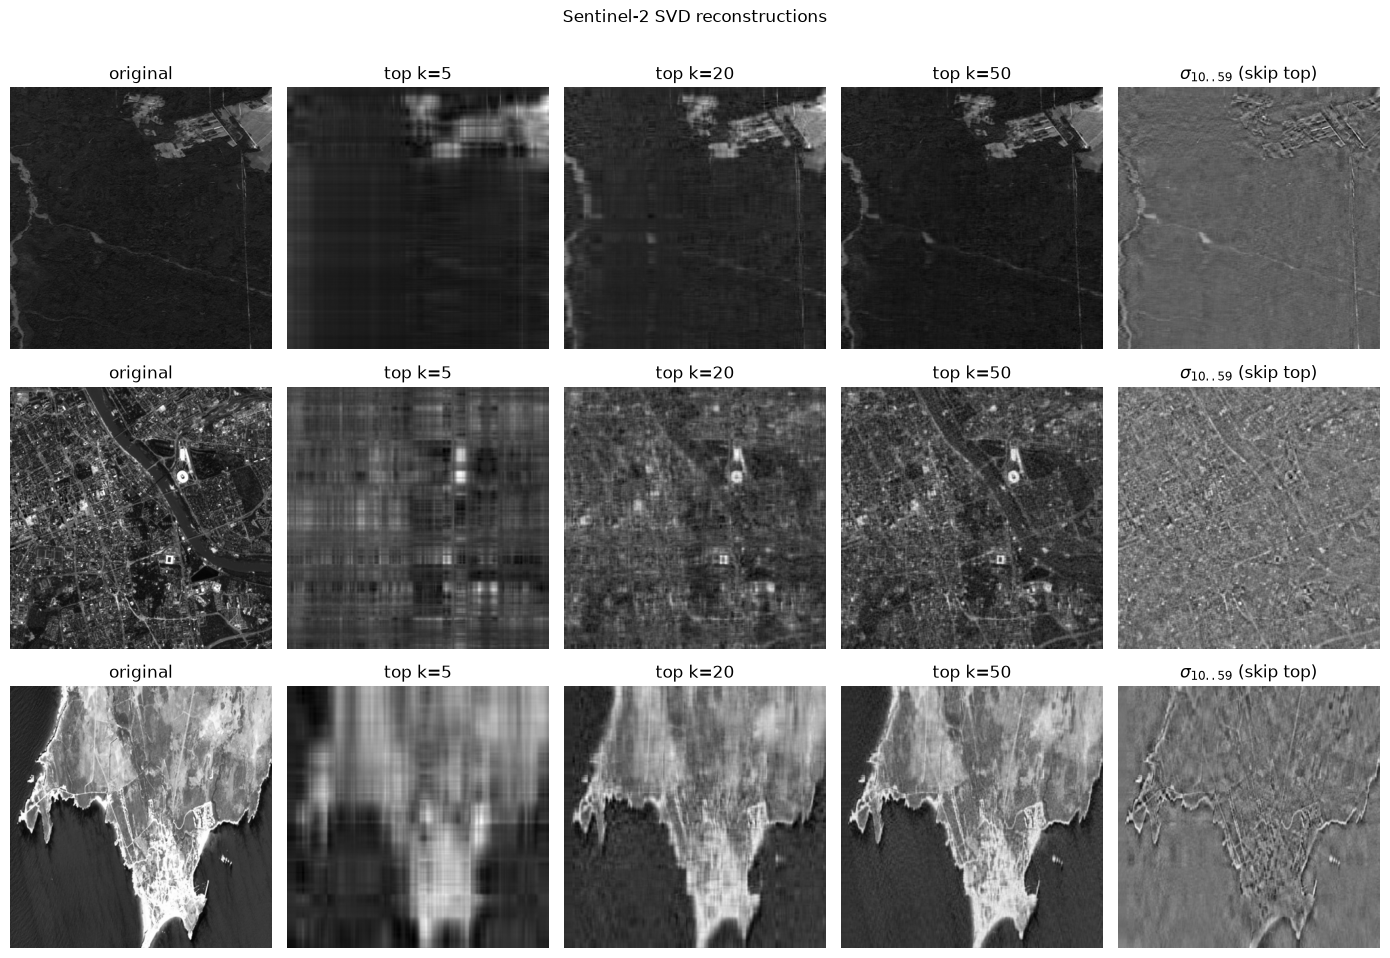

In [ ]:
ks = [5, 20, 50]
fig, axes = plt.subplots(len(svds), 5, figsize=(14, 3.2 * len(svds)))

for row, (name, (mat, U, sigma, Vt)) in enumerate(svds.items()):
    axes[row, 0].imshow(mat, cmap="gray")
    axes[row, 0].set_ylabel(name, fontsize=9)
    axes[row, 0].set_title("original")
    axes[row, 0].axis("off")

    for col, k in enumerate(ks, start=1):
        rec = (U[:, :k] * sigma[:k]) @ Vt[:k, :]
        axes[row, col].imshow(rec, cmap="gray")
        axes[row, col].set_title(f"top k={k}")
        axes[row, col].axis("off")

    j, i = 10, 60
    rec_mid = (U[:, j:i] * sigma[j:i]) @ Vt[j:i, :]
    axes[row, 4].imshow(rec_mid, cmap="gray")
    axes[row, 4].set_title(r"$\sigma_{10..59}$ (skip top)")
    axes[row, 4].axis("off")

plt.suptitle("Sentinel-2 SVD reconstructions", y=1.01)
plt.tight_layout()
plt.show()



### Observations (fill / use as lab notes)

**How many singular values are good enough?**
- Visually, **k ≈ 20** already recovers most large structures; **k ≈ 50** is usually close to the original for these 400px crops. **k = 5** only keeps coarse brightness patterns.

**Using σ instead of the largest k — better images?**
- **No.** The largest singular values carry most of the image energy (overall brightness and main spatial structure). Skipping them and keeping mid-rank terms leaves residual edges only so reconstructions look washed-out and noisy.

**Forest vs urban vs ocean**
- **Ocean (Portugal):** werid behaviour with k=20, top of the map is blurry but middle is recognizable.
- **Forest (Białowieża):** most homogeneous so singular values decay fastest becouse fewer components needed without obvious degradation.
- **Urban (Warsaw):** sharp buildings therefore needs more ranks than open water;

**Bottom line:** always keep the *largest* singular values. Homogeneous water compresses with low rank

